# Chapitre 3 - Cours 2 : Évaluation exacte, correction fonctionnelle et similarité lexicale

Ce notebook couvre la section *Exact Evaluation* du livre : la **correction
fonctionnelle** (sous-section *Functional Correctness*) et la **similarité avec des
données de référence** dans ses variantes exacte et lexicale (sous-sections *Similarity
Measurements Against Reference Data*, *Exact match*, *Lexical similarity*). La similarité
sémantique et les embeddings font l'objet du cours 3.

**Plan.**

1. Évaluation exacte ou subjective, et le harnais d'évaluation de code.
2. Correction fonctionnelle : exécuter le code généré sur des tests unitaires.
3. pass@k : définition, estimateur non biaisé (démonstration) et simulation.
4. Expérience : Qwen2.5-0.5B sur un mini-banc de dix problèmes Python.
5. Correspondance exacte et ses variantes.
6. Similarité lexicale : distance d'édition, n-grammes, BLEU et ROUGE implémentés.
7. Les limites des métriques lexicales (références incomplètes, BLEU contre tests).

In [1]:
import math
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aie import ch03_evaluation as ev
from aie import llm
from aie.diagrams import Diagram
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                          annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
llm.seed_everything(0)
pd.set_option("display.precision", 3)

## 1. Évaluation exacte ou subjective (section *Exact Evaluation*)

Le livre distingue deux régimes :

- **exact** : le verdict est sans ambiguïté (au QCM, B au lieu de A est faux, quel que
  soit le correcteur) ;
- **subjectif** : le verdict dépend de l'évaluateur (une dissertation, ou un juge IA dont
  le score change avec le modèle et le prompt, cours 3).

Deux familles de méthodes donnent des scores exacts sur des réponses **ouvertes** : la
correction fonctionnelle et la similarité avec des références. Le cas fermé
(classification) est bien connu et laissé de côté. Le schéma montre le harnais utilisé par
les benchmarks de code comme HumanEval ou MBPP, que nous allons reconstruire.

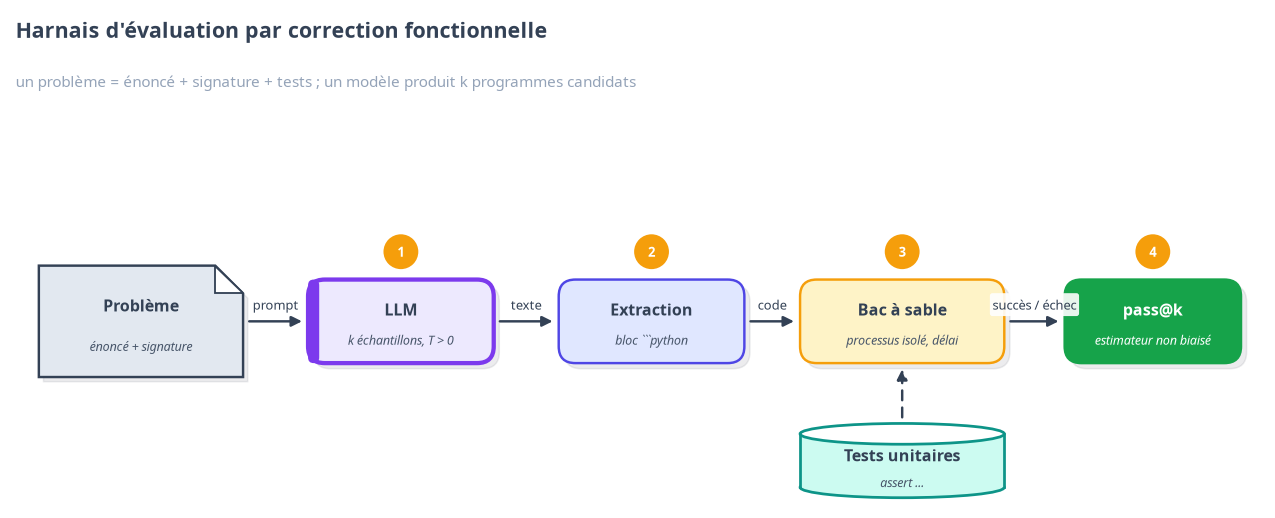

In [2]:
d = Diagram(13.5, 4.4, title="Harnais d'évaluation par correction fonctionnelle",
            subtitle="un problème = énoncé + signature + tests ; un modèle produit k programmes candidats")
d.box("pb", 1.4, 2.0, "Problème", sub="énoncé + signature", color=SLATE, kind="doc", w=2.2, h=1.2)
d.box("llm", 4.2, 2.0, "LLM", sub="k échantillons, T > 0", color=VIOLET, kind="model", w=2.0)
d.box("ext", 6.9, 2.0, "Extraction", sub="bloc ```python", color=INDIGO, w=2.0)
d.box("sb", 9.6, 2.0, "Bac à sable", sub="processus isolé, délai", color=AMBER, w=2.2)
d.box("tests", 9.6, 0.5, "Tests unitaires", sub="assert ...", color=TEAL, kind="db", w=2.2, h=0.8)
d.box("score", 12.3, 2.0, "pass@k", sub="estimateur non biaisé", color=GREEN, w=1.9, filled=True)
d.arrow("pb", "llm", "prompt"); d.arrow("llm", "ext", "texte"); d.arrow("ext", "sb", "code")
d.arrow("tests", "sb", style="dashed"); d.arrow("sb", "score", "succès / échec")
d.badge(4.2, 2.75, "1"); d.badge(6.9, 2.75, "2"); d.badge(9.6, 2.75, "3"); d.badge(12.3, 2.75, "4")
d.show()

> **À retenir.** Une évaluation est exacte quand son verdict ne dépend pas de
> l'évaluateur. Pour des sorties ouvertes, deux voies : vérifier que la sortie **fait**
> ce qu'on attend (tests) ou qu'elle **ressemble** à une référence.

## 2. Correction fonctionnelle (section *Functional Correctness*)

**Idée.** Juger un système sur ce qui compte vraiment : fait-il ce qu'on lui demande ?
C'est la métrique ultime, mais elle n'est automatisable que pour certaines tâches : le
code (on l'exécute), le SQL (on compare les résultats des requêtes), les jeux (le score),
l'optimisation (l'énergie économisée).

Reprenons l'exemple du livre : une fonction `gcd(num1, num2)`. On exécute le candidat
dans un **processus séparé** avec un délai maximal (le code généré peut boucler, planter,
voire être malveillant : en production, on utilise un vrai bac à sable), puis chaque
`assert`.

In [3]:
pb = ev.CODE_PROBLEMS[0]
candidats = {
    "correct (Euclide)": ev.REFERENCE_SOLUTIONS["pgcd"],
    "faux (minimum)": "def gcd(a, b):\n    return min(a, b)",
    "erreur de syntaxe": "def gcd(a, b)\n    return a",
    "plante au chargement": "def gcd(a, b):\n    return a\n\nprint(gcd(15, 20) / 0)",
    "boucle infinie": "def gcd(a, b):\n    while True:\n        pass",
    "lève une exception": "def gcd(a, b):\n    return a // (b - b)",
}
res = {nom: ev.run_tests(code, pb["tests"], timeout=2) for nom, code in candidats.items()}
pd.DataFrame({nom: dict(reussi=r.passed, tests_passes=f"{r.n_passed}/{r.n_tests}", erreur=r.error)
              for nom, r in res.items()}).T

,reussi,tests_passes,erreur
correct (Euclide),True,4/4,
faux (minimum),False,1/4,AssertionError
erreur de syntaxe,False,0/4,SyntaxError
plante au chargement,False,0/4,LoadError
boucle infinie,False,0/4,Timeout
lève une exception,False,0/4,ZeroDivisionError


Les tests de `gcd` : `gcd(15, 20) == 5`, `gcd(7, 13) == 1`, `gcd(100, 75) == 25`,
`gcd(12, 12) == 12`. La version « minimum » passe un test sur quatre (`gcd(12, 12)`) :
un candidat n'est déclaré correct que s'il passe **tous** les tests. La qualité d'un tel
banc d'essai dépend donc entièrement de la qualité de ses tests (couverture des cas
limites : liste vide, égalités, nombres négatifs...).

> **À retenir.** La correction fonctionnelle exécute la sortie et la confronte à des
> tests. Elle est exacte et proche de l'objectif réel, mais exige des tests de qualité
> et une exécution isolée.

## 3. pass@k : définition et estimateur non biaisé (section *Functional Correctness*)

**Définition.** Pour chaque problème, on génère $k$ programmes ; le problème est résolu si
**au moins un** passe tous les tests. pass@k est la fraction de problèmes résolus. Si un
problème est résolu avec probabilité $p$ par un échantillon, alors
$$\text{pass@}k = 1 - (1-p)^k,$$
croissant en $k$ : pass@1 $\le$ pass@3 $\le$ pass@10, comme le note le livre.

**Le problème d'estimation.** Générer exactement $k$ échantillons et regarder si l'un
passe donne un estimateur sans biais mais **très bruité** (une seule réalisation de
Bernoulli par problème). L'estimateur « plug-in » $1 - (1-\hat p)^k$ avec $\hat p = c/n$
est, lui, **biaisé** (vers le bas, par concavité).

**L'estimateur de Chen et al. (2021).** On génère $n \ge k$ échantillons, dont $c$
corrects, et on calcule
$$\widehat{\text{pass@}k} = 1 - \frac{\binom{n-c}{k}}{\binom{n}{k}}.$$
*Interprétation* : c'est la probabilité qu'un sous-ensemble de $k$ échantillons tiré
sans remise parmi les $n$ contienne au moins un succès (loi hypergéométrique).

*Démonstration du non-biais.* Numérotons les $n$ échantillons, i.i.d. de succès $p$.
Pour un sous-ensemble fixé $S$ de taille $k$, l'indicatrice « tous les éléments de $S$
échouent » a pour espérance $(1-p)^k$. Or
$\binom{n-c}{k} = \sum_{|S| = k} \mathbb 1[\text{tous les éléments de } S \text{ échouent}]$
(on compte les sous-ensembles inclus dans les $n - c$ échecs). Par linéarité,
$\mathbb E\big[\binom{n-c}{k}\big] = \binom nk (1-p)^k$, d'où
$\mathbb E\big[\widehat{\text{pass@}k}\big] = 1 - (1-p)^k$. $\blacksquare$

*Calcul stable.* Les coefficients binomiaux débordent vite ; on utilise
$\frac{\binom{n-c}{k}}{\binom nk} = \prod_{i=n-c+1}^{n}\big(1 - \frac ki\big)$
(implémenté dans `ev.pass_at_k`).

**Simulation.** Un problème de difficulté $p = 0{,}1$, $k = 5$ : comparons sur 20 000
répétitions trois estimateurs.

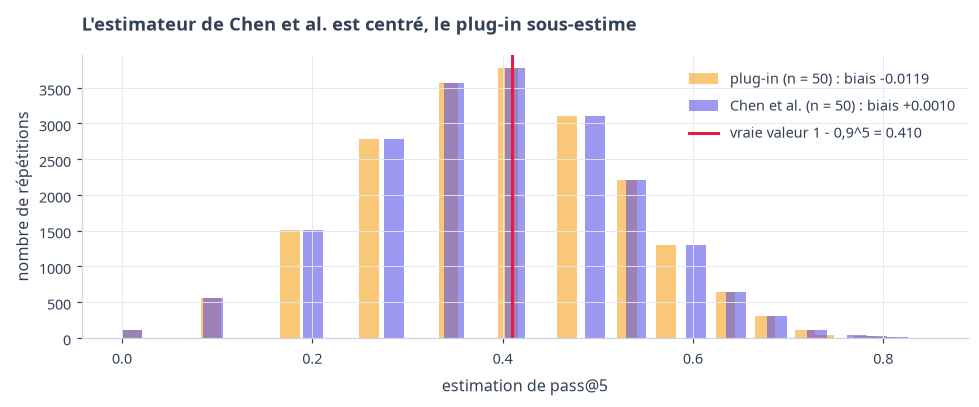

,moyenne,biais,écart-type
k échantillons seulement,0.416,0.007,0.493
plug-in (n = 50),0.398,-0.012,0.136
Chen et al. (n = 50),0.411,0.001,0.139


In [4]:
rng = np.random.default_rng(0)
p_vrai, k, n = 0.10, 5, 50
reps = 20000
naif, plugin, chen = [], [], []
for _ in range(reps):
    s = rng.random(n) < p_vrai
    naif.append(float(s[:k].any()))
    plugin.append(1 - (1 - s.mean()) ** k)
    chen.append(ev.pass_at_k(n, int(s.sum()), k))
vrai = ev.pass_at_k_true(p_vrai, k)
est = pd.DataFrame({"k échantillons seulement": naif, f"plug-in (n = {n})": plugin, f"Chen et al. (n = {n})": chen})
resume = pd.DataFrame({"moyenne": est.mean(), "biais": est.mean() - vrai, "écart-type": est.std()})
fig, ax = plt.subplots(figsize=(9, 3.8))
for (nom, col), c in zip(est.items(), [GRAY, AMBER, INDIGO]):
    if nom.startswith("k "):
        continue
    ax.hist(col, bins=40, alpha=0.55, color=c, label=f"{nom} : biais {col.mean() - vrai:+.4f}")
ax.axvline(vrai, color=ROSE, lw=2, label=f"vraie valeur 1 - 0,9^5 = {vrai:.3f}")
ax.set_xlabel("estimation de pass@5"); ax.set_ylabel("nombre de répétitions")
ax.set_title("L'estimateur de Chen et al. est centré, le plug-in sous-estime")
ax.legend()
plt.tight_layout(); plt.show()
resume

L'estimateur naïf (k échantillons) est sans biais mais son écart-type est énorme (c'est
une variable 0/1). L'estimateur de Chen et al. est sans biais **et** bien plus précis,
car il exploite les $n = 50$ échantillons. Le plug-in sous-estime systématiquement.
Visualisons enfin $\widehat{\text{pass@}k}$ en fonction de $k$ pour quelques valeurs de
$c$ sur $n = 20$ : un problème résolu une fois sur vingt a déjà un pass@10 de 50 %.

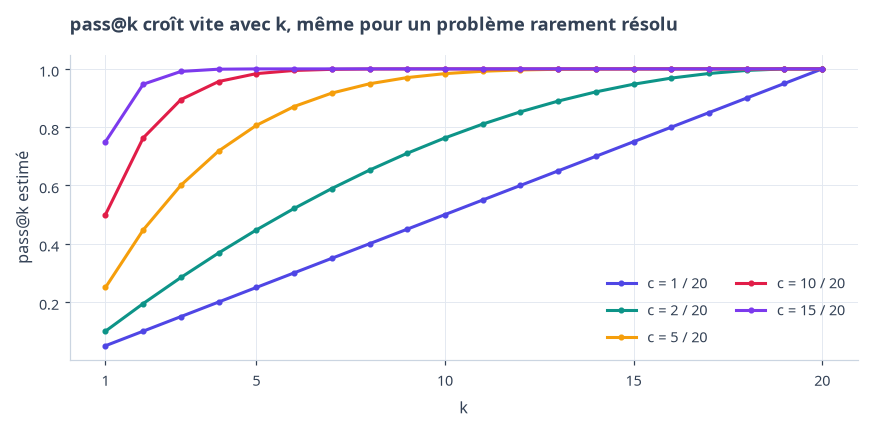

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ks = np.arange(1, 21)
for c, col in zip([1, 2, 5, 10, 15], COLORS):
    ax.plot(ks, [ev.pass_at_k(20, c, kk) for kk in ks], "o-", ms=3, color=col, label=f"c = {c} / 20")
ax.set_xlabel("k"); ax.set_ylabel("pass@k estimé"); ax.set_xticks([1, 5, 10, 15, 20])
ax.set_title("pass@k croît vite avec k, même pour un problème rarement résolu")
ax.legend(ncol=2)
plt.tight_layout(); plt.show()

> **À retenir.** pass@k mesure la probabilité qu'au moins un des $k$ essais soit correct.
> On l'estime sans biais avec $n \ge k$ échantillons par
> $1 - \binom{n-c}{k}/\binom nk$, plus précis que k essais isolés et sans le biais du
> plug-in.